# Numerical methods for two-point boundary value problems

## Finite differences with special approximations

### Variable diffusion coefficient

Let us return to the boundary value problem

$$
-(k(x)u'(x))'+q(x)u(x)=f(x),\quad a<x<b, \tag{1}
$$

$$
u(a)=u_a,\quad u(b)=u_b. \tag{2}
$$

We assume $k(x)\geq k_0>0$ and $q(x)\geq0$. Compared with the case $k\equiv1$, the new question is how to approximate the divergence of the flux $w(x)=-k(x)u'(x)$. On a uniform grid $x_i=a+ih$, $i=0,\ldots,N$, with $N\geq2$ and $h=(b-a)/N$, write $x_{i+1/2}=(x_i+x_{i+1})/2$ and $k_{i+1/2}=k(x_{i+1/2})$. For $1\leq i\leq N-1$ approximate $w'(x_i)$ by

$$
w'(x_i)\approx\frac{w(x_{i+1/2})-w(x_{i-1/2})}{h}. \tag{3}
$$

For the fluxes at the adjacent midpoints, use

$$
w(x_{i+1/2})\approx-k_{i+1/2}\frac{u(x_{i+1})-u(x_i)}{h}, \tag{4}
$$

$$
w(x_{i-1/2})\approx-k_{i-1/2}\frac{u(x_i)-u(x_{i-1})}{h}. \tag{5}
$$

This gives

$$
-(ku')'(x_i)\approx-\frac{1}{h}\left(k_{i+1/2}\frac{u(x_{i+1})-u(x_i)}{h}
-k_{i-1/2}\frac{u(x_i)-u(x_{i-1})}{h}\right). \tag{6}
$$

**Definition 1 (conservative difference scheme).** The diffusion term is approximated by a difference of numerical fluxes. Neighboring equations use the same flux through their common face with opposite signs. With $u_i=u^h(x_i)$, $q_i=q(x_i)$ and $f_i=f(x_i)$, set

$$
L^h[u^h](x_i)=
-\frac{1}{h}\left(k_{i+1/2}\frac{u_{i+1}-u_i}{h}-k_{i-1/2}\frac{u_i-u_{i-1}}{h}\right)+q_i u_i. \tag{7}
$$

The grid equations are

$$
L^h[u^h](x_i)=f_i,\quad 1\leq i\leq N-1,\quad u_0=u_a,\quad u_N=u_b. \tag{8}
$$

Multiplying the interior equations by $h^2$ gives the tridiagonal system. Its coefficients $a_i,b_i,c_i$ multiplying $u_{i-1},u_i,u_{i+1}$ satisfy the sign conditions used in the discrete maximum principle,

$$
a_i<0,\quad c_i<0,\quad b_i>0,\quad a_i+b_i+c_i\geq0. \tag{9}
$$

**Proposition 1 (maximum principle and solvability).** For a tridiagonal system with (9), nonpositive right-hand sides and nonpositive boundary values imply nonpositive nodal values. In particular, the Dirichlet system has a unique solution for every choice of data.

**Proof.** At the rightmost node attaining a positive maximum, $u_{i-1}\leq u_i$ and $u_{i+1}<u_i$. Hence the left-hand side strictly exceeds $(a_i+b_i+c_i)u_i\geq0$, a contradiction. Applied to a homogeneous solution and its negative, the result gives uniqueness. Existence follows because the system is square. $\square$

For the coefficients $a_i=-k_{i-1/2}$, $b_i=k_{i-1/2}+k_{i+1/2}+h^2q_i$, and $c_i=-k_{i+1/2}$, one has $a_i+b_i+c_i=h^2q_i\geq0$. The scheme is stable in the maximum norm with a bound independent of the step, as shown below for the nonuniform grid as well. If $k\in C^3[a,b]$ and $q,f\in C^2[a,b]$, then $u\in C^4[a,b]$. Taylor expansion at each midpoint gives a flux error with leading term proportional to $h^2 k u'''$ and a remainder $O(h^3)$. The leading terms on adjacent faces differ by $O(h^3)$, so the nodal residual and the maximum nodal error are $O(h^2)$.

There is another possible approach. Expanding $(ku')'=ku''+k'u'$, one can approximate it by

$$
k(x_i)\frac{u(x_{i-1})-2u(x_i)+u(x_{i+1})}{h^2}
+k'(x_i)\frac{u(x_{i+1})-u(x_{i-1})}{2h}. \tag{10}
$$

The corresponding operator is

$$
L^h[u^h](x_i)=-k(x_i)\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}
-k'(x_i)\frac{u_{i+1}-u_{i-1}}{2h}+q_i u_i. \tag{11}
$$

The coefficients of the grid system after multiplication by $h^2$ are

$$
\begin{aligned}
a_i&=-k(x_i)+\tfrac h2 k'(x_i),\\
b_i&=2k(x_i)+h^2q_i,\\
c_i&=-k(x_i)-\tfrac h2 k'(x_i).
\end{aligned} \tag{12}
$$

Both off-diagonal coefficients are strictly negative exactly when

$$
h\max_{1\leq i\leq N-1}\frac{|k'(x_i)|}{k(x_i)}<2. \tag{13}
$$

Under (13), (9) holds. A rapidly varying $k$ can force a very small step to meet this condition. The flux approximation (7) has the required signs for every step.

### Nonuniform grids

Let $h_i=x_i-x_{i-1}$, $h_{\max}=\max_i h_i$, and $h_{i+1/2}=x_{i+1/2}-x_{i-1/2}=(h_i+h_{i+1})/2$ at an interior node. Replacing the three occurrences of $h$ in (3), (4), and (5) by $h_{i+1/2}$, $h_{i+1}$, and $h_i$, respectively, gives

$$
L^h[u^h](x_i)=
-\frac{1}{h_{i+1/2}}\left(k_{i+1/2}\frac{u_{i+1}-u_i}{h_{i+1}}
-k_{i-1/2}\frac{u_i-u_{i-1}}{h_i}\right)+q_i u_i. \tag{14}
$$

The sign conditions (9) still hold. To see stability, take the solution $z^h$ of the nonuniform scheme with $q=0$, unit right-hand side, and zero boundary values. By Proposition 1, $z^h\geq0$. Its numerical fluxes increase by $h_{i+1/2}$ at each interior node, and their weighted sum with positive weights $h_{i+1}/k_{i+1/2}$ is zero by the boundary conditions. Each flux therefore has absolute value at most $b-a$, and summing the nodal increments gives $\|z^h\|_\infty\leq (b-a)^2/k_0$. Comparing $u^h$ and $-u^h$ with $\max\{|u_a|,|u_b|\}+\max_i|f_i|\,z^h$ gives a bound independent of the grid. By linearity the same argument applies to perturbations of the data.

For the smooth data of the uniform-grid case, the nodal residual is $O(h_{\max}^2)$ when $\max_i|h_{i+1}-h_i|=O(h_{\max}^2)$. Indeed, the leading asymmetry in the flux difference and the difference of the two face flux errors after division by $h_{i+1/2}$ are $O(|h_{i+1}-h_i|+h_{\max}^2)$. The stability bound then gives second-order convergence in the maximum nodal norm.

### Upwind differences

For heat transfer in a moving medium, the equation can include a convection term,

$$
-(ku')'+vu'+qu=f. \tag{15}
$$

Here $v(x)$ is proportional to the flow velocity. The centered approximation adds

$$
v_i\frac{u_{i+1}-u_{i-1}}{2h},\quad v_i=v(x_i), \tag{16}
$$

to (7). After multiplication by $h^2$, the interior coefficients are

$$
\begin{aligned}
a_i&=-k_{i-1/2}-\tfrac h2v_i,\\
b_i&=k_{i-1/2}+k_{i+1/2}+h^2q_i,\\
c_i&=-k_{i+1/2}+\tfrac h2v_i .
\end{aligned} \tag{17}
$$

The exact strict sign condition is $-2k_{i-1/2}<hv_i<2k_{i+1/2}$. A convenient sufficient condition is

$$
h|v_i|<2\min\{k_{i-1/2},k_{i+1/2}\}\quad\text{at every interior node}. \tag{18}
$$

For high velocities, this condition can impose a small step.

**Definition 2 (upwind difference).** Choose the one-sided difference from the incoming side of the flow,

$$
v_i u'(x_i)\approx v_i^+\frac{u(x_i)-u(x_{i-1})}{h}
+v_i^-\frac{u(x_{i+1})-u(x_i)}{h}, \tag{19}
$$

where

$$
v_i^+=\max\{v_i,0\},\quad v_i^-=\min\{v_i,0\}. \tag{20}
$$

The backward difference is used for $v_i>0$, and the forward difference for $v_i<0$. This choice gives

$$
\begin{aligned}
a_i&=-k_{i-1/2}-hv_i^+,\\
b_i&=k_{i-1/2}+k_{i+1/2}+h(v_i^+-v_i^-)+h^2q_i,\\
c_i&=-k_{i+1/2}+hv_i^- .
\end{aligned} \tag{21}
$$

Since $a_i+b_i+c_i=h^2q_i$, the maximum principle holds for any step size. The upwind approximation of the convection term is generally first-order accurate for smooth solutions.

### Discontinuous coefficients

Heterogeneous media can lead to discontinuous coefficients. Suppose $k,q,f$ are bounded and piecewise continuous with finitely many jumps in $(a,b)$, with $k\geq k_0>0$ and $q\geq0$ away from the jumps.

**Definition 3 (solution with interface conditions).** The solution $u$ is continuous on $[a,b]$, satisfies (2), and is differentiable between interfaces. The flux $w=-ku'$ extends continuously across each interface and satisfies

$$
w'(x)+q(x)u(x)=f(x) \tag{22}
$$

between interfaces. These conditions describe perfect contact and no concentrated sources at the interfaces. The derivative $u'$ can jump when $k$ jumps.

Integrate (22) over the control volume $[x_{i-1/2},x_{i+1/2}]$. Flux continuity gives the balance even when the cell contains an interface,

$$
w(x_{i+1/2})-w(x_{i-1/2})+\int_{x_{i-1/2}}^{x_{i+1/2}}qu\,dx
=\int_{x_{i-1/2}}^{x_{i+1/2}} f\,dx. \tag{23}
$$

Approximate $u$ in the reaction integral by $u(x_i)$ and divide by the control-volume length,

$$
\frac{w(x_{i+1/2})-w(x_{i-1/2})}{h_{i+1/2}}+q_i^h u(x_i)\approx f_i^h, \tag{24}
$$

where

$$
\begin{aligned}
q_i^h&=\frac{1}{h_{i+1/2}}\int_{x_{i-1/2}}^{x_{i+1/2}} q(x)\,dx,\\
f_i^h&=\frac{1}{h_{i+1/2}}\int_{x_{i-1/2}}^{x_{i+1/2}} f(x)\,dx .
\end{aligned} \tag{25}
$$

Next, integrate $u'=-w/k$ between consecutive grid nodes and approximate $w$ by its midpoint value,

$$
u(x_{i+1})-u(x_i)=-\int_{x_i}^{x_{i+1}}\frac{w(x)}{k(x)}\,dx
\approx -w(x_{i+1/2})\int_{x_i}^{x_{i+1}}\frac{dx}{k(x)}. \tag{26}
$$

Thus

$$
w(x_{i+1/2})\approx-\kappa_{i+1/2}\frac{u(x_{i+1})-u(x_i)}{h_{i+1}}, \tag{27}
$$

where the *effective conductivity* is the harmonic mean

$$
\kappa_{i+1/2}=\left(\frac{1}{h_{i+1}}\int_{x_i}^{x_{i+1}}\frac{dx}{k(x)}\right)^{-1}. \tag{28}
$$

The quantity averaged inside the parentheses is the thermal resistivity $1/k$. For example, if $k=1$ and $k=4$ on the two halves of a grid interval, then $\kappa=(\tfrac12+\tfrac18)^{-1}=8/5$. For constant flux, (27) is exact.

Substituting (27) into (24) gives

$$
-\frac{1}{h_{i+1/2}}\left(\kappa_{i+1/2}\frac{u_{i+1}-u_i}{h_{i+1}}
-\kappa_{i-1/2}\frac{u_i-u_{i-1}}{h_i}\right)+q_i^h u_i=f_i^h,\quad 1\leq i\leq N-1, \tag{29}
$$

together with

$$
u_0=u_a,\quad u_N=u_b. \tag{30}
$$

**Remark 1.** The stencil is the same at every interior node, even when an interface lies between nodes. The integrals defining its coefficients still need to account for the jumps. The rate on a particular grid depends on the data and how those integrals are evaluated.

### Approximation of boundary conditions

The values prescribed by Dirichlet conditions can be imposed directly. Consider instead a left Neumann condition specifying the flux in the positive $x$ direction,

$$
-k(a)u'(a)=w_a. \tag{31}
$$

We retain the Dirichlet value at the right end. A simple forward approximation gives

$$
-k(a)\frac{u_1-u_0}{h}=w_a. \tag{32}
$$

If $u$ has three continuous derivatives near $a$, Taylor's formula gives

$$
\frac{u(a+h)-u(a)}{h}=u'(a)+\frac h2u''(a)+O(h^2). \tag{33}
$$

Thus (32) has first-order consistency and can reduce the order of the whole scheme. If $k$ is continuously differentiable and the coefficients extend continuously to $a$ from the right, (1) gives

$$
k(a)u''(a)=-k'(a)u'(a)+q(a)u(a)-f(a). \tag{34}
$$

Using (31) to eliminate $u'(a)$, we obtain

$$
-k(a)\frac{u(a+h)-u(a)}{h}
=w_a+\frac h2\left(-\frac{k'(a)}{k(a)}w_a-q(a)u(a)+f(a)\right)+O(h^2). \tag{35}
$$

This gives a second-order approximation of the boundary condition,

$$
-k(a)\frac{u_1-u_0}{h}+\frac h2 q(a)u_0
=\left(1-\frac h2\frac{k'(a)}{k(a)}\right)w_a+\frac h2 f(a). \tag{36}
$$

The balance method also gives a boundary approximation. Integrating (22) from $x_0=a$ to $x_{1/2}=a+h/2$ yields

$$
w(x_{1/2})-w_a+\int_{x_0}^{x_{1/2}}qu\,dx=\int_{x_0}^{x_{1/2}}f\,dx. \tag{37}
$$

With the harmonic conductivity from (28) and the half-cell averages, the resulting equation is

$$
-\kappa_{1/2}\frac{u_1-u_0}{h}+\frac h2 q_0^h u_0=w_a+\frac h2 f_0^h, \tag{38}
$$

where

$$
q_0^h=\frac2h\int_{x_0}^{x_{1/2}}q\,dx,\quad f_0^h=\frac2h\int_{x_0}^{x_{1/2}}f\,dx. \tag{39}
$$

If $k\in C^2$ and $u\in C^3$ near $a$ and $q$ is bounded, substituting the exact solution in this unscaled flux balance leaves a residual $O(h^2)$. The flux approximation at $x_{1/2}$ is second order, and replacing $u(x)$ by $u(a)$ in the reaction integral also gives an $O(h^2)$ error.

## Projection methods and the finite element method

### Variational formulation of the boundary value problem

Alongside finite differences, Ritz and Galerkin methods are widely used for boundary value problems. The finite element method combines a projection formulation with a basis built on a partition of the domain.

**Definition 4 (variational functional).** A functional assigns a number to a function. In a variational problem the solution is sought as a stationary point of a functional such as

$$
J(u)=\int_a^b F(x,u,u')\,dx. \tag{40}
$$

Often $J$ represents the potential energy of a physical system. We work on the affine space $U=\{u\in H^1(a,b):u(a)=u_a,\ u(b)=u_b\}$, with prescribed values

$$
u(a)=u_a,\quad u(b)=u_b. \tag{41}
$$

In one dimension, functions in $H^1(a,b)$ have continuous representatives and square-integrable weak first derivatives. Variations vanish at the endpoints. For smooth $F$ and a smooth stationary point, the Euler–Lagrange equation is

$$
-\frac{d}{dx}F_{u'}(x,u,u')+F_u(x,u,u')=0. \tag{42}
$$

Now consider the quadratic functional

$$
J(u)=\frac12\int_a^b\bigl(k(u')^2+qu^2\bigr)\,dx-\int_a^b fu\,dx. \tag{43}
$$

Its Euler–Lagrange equation is

$$
-(ku')'+qu=f. \tag{44}
$$

**Theorem 1 (energy minimization).** For bounded piecewise continuous $k,q,f$ with $k\geq k_0>0$ and $q\geq0$, the weak solution of (44), (41) is the unique $u\in U$ satisfying

$$
J(u)=\min_{v\in U}J(v). \tag{45}
$$

**Proof.** A minimizer has zero first variation against every $\eta\in H_0^1(a,b)$. This gives the weak equation $\int_a^b(ku'\eta'+qu\eta)\,dx=\int_a^b f\eta\,dx$. Conversely, for a weak solution, expansion of the quadratic functional gives $J(u+\eta)-J(u)=\tfrac12\int_a^b(k(\eta')^2+q\eta^2)\,dx>0$ for every nonzero $\eta\in H_0^1(a,b)$. The bilinear form is coercive on $H_0^1(a,b)$ by the Poincaré inequality, so the weak solution exists by the Lax–Milgram theorem after subtracting a function with the prescribed boundary values. $\square$

This formulation requires only first weak derivatives. With the interface conditions above, the flux has weak derivative $f-qu$ and is continuous across jumps.

### The Ritz method

Let $\varphi_0,\varphi_1,\ldots,\varphi_N\in H^1(a,b)$ be linearly independent basis functions. Seek an approximation of the form

$$
u^N(x)=\sum_{j=0}^N\alpha_j\varphi_j(x). \tag{46}
$$

Choose the endpoint values so that $\varphi_0(a)=\varphi_N(b)=1$ and all other basis values at each endpoint are zero. Then the boundary conditions reduce to

$$
\alpha_0=u_a,\quad \alpha_N=u_b. \tag{47}
$$

**Definition 5 (Ritz approximation).** Let $U^N$ be the set of functions of the form (46) satisfying (47). The Ritz solution minimizes $J$ on this finite-dimensional affine space,

$$
J(u^N)=\min_{v\in U^N}J(v). \tag{48}
$$

At the minimum the derivatives with respect to the free coefficients vanish,

$$
\frac{\partial}{\partial\alpha_i}J\left(\sum_{j=0}^{N}\alpha_j\varphi_j\right)=0,
\quad i=1,\ldots,N-1. \tag{49}
$$

For the functional (43), write $J=\tfrac12B(u^N,u^N)-\int_a^b fu^N\,dx$, where $B(s,t)=\int_a^b(ks't'+qst)\,dx$. By symmetry of $B$ the derivative is

$$
\frac{\partial J}{\partial\alpha_i}
=\int_a^b\bigl(k(u^N)'\varphi_i'+qu^N\varphi_i\bigr)\,dx
-\int_a^b f\varphi_i\,dx. \tag{50}
$$

Substitution of (46) gives the equation

$$
\sum_{j=0}^{N}\alpha_j\int_a^b(k\varphi_j'\varphi_i'+q\varphi_j\varphi_i)\,dx
=\int_a^b f\varphi_i\,dx. \tag{51}
$$

The resulting system is

$$
\sum_{j=0}^{N}a_{ij}\alpha_j=b_i,\quad i=1,\ldots,N-1, \tag{52}
$$

$$
\alpha_0=u_a,\quad\alpha_N=u_b, \tag{53}
$$

where

$$
a_{ij}=\int_a^b(k\varphi_i'\varphi_j'+q\varphi_i\varphi_j)\,dx,\quad
b_i=\int_a^b f\varphi_i\,dx. \tag{54}
$$

Eliminating the boundary coefficients gives

$$
A\alpha=d,\quad d_i=b_i-a_{i0}u_a-a_{iN}u_b, \tag{55}
$$

where $A=(a_{ij})_{i,j=1}^{N-1}$ and $\alpha=(\alpha_1,\ldots,\alpha_{N-1})^{\mathsf T}$.

**Proposition 2.** The interior matrix $A$ is symmetric positive definite.

**Proof.** Symmetry follows from (54). For $z\ne0$, let $z_h=\sum_{j=1}^{N-1}z_j\varphi_j$. The basis is linearly independent and $z_h$ has zero boundary values. Thus $z^{\mathsf T}Az=B(z_h,z_h)\geq k_0\int_a^b(z_h')^2\,dx>0$. $\square$

### Projection formulation of a boundary value problem

Consider the boundary value problem

$$
L[u]=f,\quad a<x<b, \tag{56}
$$

$$
u(a)=u_a,\quad u(b)=u_b. \tag{57}
$$

A variational principle follows directly when $L[u]-f$ is an Euler–Lagrange expression. For example, the operator in

$$
-(ku')'+vu'+qu=f \tag{58}
$$

is generally nonsymmetric in its unweighted weak form when $v$ is present. In one dimension an integrating factor can nevertheless give a variational formulation. If $v/k$ is integrable, put $\mu(x)=\exp(-\int_a^x v(s)/k(s)\,ds)$. Multiplying (58) by $\mu$ gives $-(\mu k u')'+\mu q u=\mu f$.

**Definition 6 (test function and integral formulation).** A test function $\varphi$ vanishes at the endpoints. One may start with continuous piecewise smooth test functions, or use the space $\Phi=H_0^1(a,b)$ in the weak formulation. For a classical solution, multiplying (56) by $\varphi$ and integrating gives

$$
\int_a^b L[u]\,\varphi\,dx=\int_a^b f\varphi\,dx. \tag{59}
$$

Conversely, if (59) holds for all smooth test functions of compact support and the residual is continuous, the fundamental lemma of the calculus of variations implies $L[u]=f$ in $(a,b)$.

For (58), the integral identity is

$$
\int_a^b\bigl(-(ku')'+vu'+qu\bigr)\varphi\,dx=\int_a^b f\varphi\,dx. \tag{60}
$$

Integration by parts removes the derivative of the flux from the integral,

$$
-\int_a^b(ku')'\varphi\,dx=-[ku'\varphi]_a^b+\int_a^b ku'\varphi'\,dx
=\int_a^b ku'\varphi'\,dx. \tag{61}
$$

The resulting weak problem is to find $u\in U$ satisfying

$$
\int_a^b(ku'\varphi'+vu'\varphi+qu\varphi)\,dx=\int_a^b f\varphi\,dx
\quad\text{for all }\varphi\in\Phi. \tag{62}
$$

Only the first weak derivative of $u$ is needed. The weak form is therefore useful when the coefficients are discontinuous.

### The Galerkin method

**Definition 7 (Galerkin approximation).** Seek the approximate solution as in the Ritz method,

$$
u^N(x)=\sum_{j=0}^N\alpha_j\varphi_j(x), \tag{63}
$$

and require the weak identity only for tests from the homogeneous trial space, spanned by $\varphi_i$, $i=1,\ldots,N-1$. If $B_v(s,t)=\int_a^b(ks't'+vs't+qst)\,dx$, then the equations are

$$
B_v(u^N,\varphi_i)=\int_a^b f\varphi_i\,dx,\quad i=1,\ldots,N-1. \tag{64}
$$

Substituting (63) gives

$$
\sum_{j=0}^N\alpha_j\int_a^b(k\varphi_j'\varphi_i'+v\varphi_j'\varphi_i+q\varphi_j\varphi_i)\,dx
=\int_a^b f\varphi_i\,dx,\quad i=1,\ldots,N-1, \tag{65}
$$

$$
\alpha_0=u_a,\quad\alpha_N=u_b. \tag{66}
$$

**Corollary 1 (agreement with the Ritz method).** For $v\equiv0$, (65), (66) coincide with (52), (53). Thus Ritz and Galerkin give the same solution for (44), (41) when they use the same approximation space.

**Remark 2.** A finite difference solution gives values at grid nodes. To evaluate between nodes, choose an interpolation. In contrast, (46) already gives a function defined on the whole interval. With general bases, projection matrices can be dense. The finite element method obtains sparse matrices by choosing basis functions with local support.

### The finite element method

The finite element method is a projection method based on a partition of the domain and locally supported basis functions. An early use of piecewise linear trial functions was given by R. Courant in 1943. The method developed through work in structural mechanics in the 1950s and through mathematical analysis in the following decades.

**Definition 8 (finite elements and local basis).** Partition the domain into elementary subdomains called finite elements. The basis functions have a simple form on each element, usually a polynomial, and each basis function is supported on a small number of neighboring elements. In one dimension the elements are the intervals $[x_{i-1},x_i]$, of length $h_i$, determined by $a=x_0<x_1<\cdots<x_N=b$.

For the problem (44), (41), take the piecewise linear *hat functions* for $j=1,\ldots,N-1$,

$$
\varphi_j(x)=
\begin{cases}
(x-x_{j-1})/h_j,&x_{j-1}\leq x\leq x_j,\\
(x_{j+1}-x)/h_{j+1},&x_j<x\leq x_{j+1},\\
0,&\text{otherwise}.
\end{cases} \tag{67}
$$

The two boundary basis functions each occupy one element,

$$
\varphi_0(x)=
\begin{cases}
(x_1-x)/h_1,&x_0\leq x\leq x_1,\\
0,&\text{otherwise},
\end{cases} \tag{68}
$$

$$
\varphi_N(x)=
\begin{cases}
(x-x_{N-1})/h_N,&x_{N-1}\leq x\leq x_N,\\
0,&\text{otherwise}.
\end{cases} \tag{69}
$$

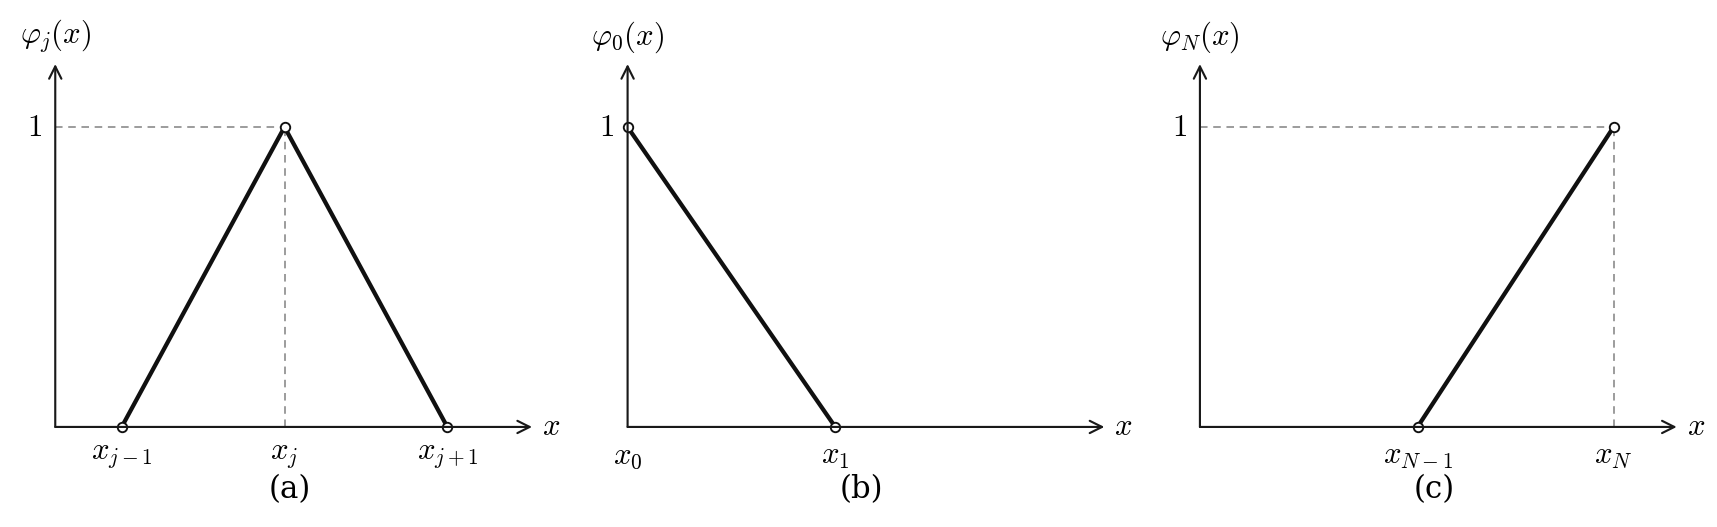

***Figure 1.*** *Piecewise linear basis functions at (a) an interior node, (b) the left endpoint, and (c) the right endpoint*

We seek an approximate solution

$$
u^N(x)=\sum_{j=0}^N\alpha_j\varphi_j(x). \tag{70}
$$

Because $\varphi_j(x_i)=\delta_{ij}$, the coefficients are the nodal values $\alpha_j=u^N(x_j)=u_j^h$. Thus

$$
u^N(x)=\sum_{j=0}^N u_j^h\varphi_j(x). \tag{71}
$$

The basis functions and their derivatives overlap on an interval of positive length only for $|i-j|\leq1$. Hence the matrix entries

$$
a_{ij}=\int_a^b(k\varphi_i'\varphi_j'+q\varphi_i\varphi_j)\,dx \tag{72}
$$

vanish for $|i-j|>1$. The interior equations therefore form a tridiagonal system,

$$
a_{i,i-1}u_{i-1}^h+a_{i,i}u_i^h+a_{i,i+1}u_{i+1}^h=b_i,\quad 1\leq i\leq N-1, \tag{73}
$$

$$
u_0^h=u_a,\quad u_N^h=u_b. \tag{74}
$$

Away from the grid nodes, the derivative of the interior hat function is

$$
\varphi_j'(x)=
\begin{cases}
1/h_j,&x_{j-1}<x<x_j,\\
-1/h_{j+1},&x_j<x<x_{j+1},\\
0,&\text{otherwise}.
\end{cases} \tag{75}
$$

Substituting these derivatives in the integrals gives

$$
a_{i,i-1}=-\frac{\bar k_{i-1/2}}{h_i}+h_{i+1/2}Q_{i,-}, \tag{76}
$$

$$
a_{i,i+1}=-\frac{\bar k_{i+1/2}}{h_{i+1}}+h_{i+1/2}Q_{i,+}, \tag{77}
$$

$$
\begin{aligned}
a_{i,i}&=\frac{\bar k_{i-1/2}}{h_i}+\frac{\bar k_{i+1/2}}{h_{i+1}}+h_{i+1/2}Q_i,\\
b_i&=h_{i+1/2}F_i,
\end{aligned} \tag{78}
$$

where the conductivity is averaged arithmetically on each element and the reaction and source terms are weighted by the basis functions,

$$
\begin{aligned}
\bar k_{i-1/2}&=\frac1{h_i}\int_{x_{i-1}}^{x_i}k(x)\,dx,\\
Q_{i,\pm}&=\frac1{h_{i+1/2}}\int_{x_{i-1}}^{x_{i+1}}q(x)\varphi_i(x)\varphi_{i\pm1}(x)\,dx,
\end{aligned} \tag{79}
$$

$$
\begin{aligned}
Q_i&=\frac1{h_{i+1/2}}\int_{x_{i-1}}^{x_{i+1}}q(x)\varphi_i^2(x)\,dx,\\
F_i&=\frac1{h_{i+1/2}}\int_{x_{i-1}}^{x_{i+1}}f(x)\varphi_i(x)\,dx.
\end{aligned} \tag{80}
$$

**Definition 9 (projection–difference scheme).** The finite element equations (73), (74) form a projection–difference scheme. The solution is unique by Proposition 2. For example, for $k\in C^1[a,b]$ with $k\geq k_0>0$, bounded $q\geq0$, and $f\in L^2(a,b)$, the piecewise linear Galerkin solution with exact integrals has error $O(h_{\max})$ in $H^1(a,b)$ and $O(h_{\max}^2)$ in $L^2(a,b)$ by the usual energy and duality estimates.

Dividing (73) by $h_{i+1/2}$ gives a form close to the conservative difference scheme (29), (30),

$$
\begin{aligned}
&-\frac1{h_{i+1/2}}\left(\bar k_{i+1/2}\frac{u_{i+1}^h-u_i^h}{h_{i+1}}
-\bar k_{i-1/2}\frac{u_i^h-u_{i-1}^h}{h_i}\right)\\
&\quad + Q_{i,-}u_{i-1}^h+Q_i u_i^h+Q_{i,+}u_{i+1}^h=F_i,\quad 1\leq i\leq N-1,
\end{aligned} \tag{81}
$$

$$
u_0^h=u_a,\quad u_N^h=u_b. \tag{82}
$$

The difference lies in the coefficient averages and the reaction coupling to neighboring nodes.

**Remark 3 (quadrature for smooth coefficients).** A simple quadrature takes each coefficient at its element midpoint and integrates the basis factors exactly. For example,

$$
\int_{x_{i-1}}^{x_i}k(x)\,dx\approx h_i k(x_{i-1/2}), \tag{83}
$$

$$
\int_{x_{i-1}}^{x_i}q(x)\varphi_i(x)\varphi_{i-1}(x)\,dx
\approx \frac{h_i}{6}q(x_{i-1/2}), \tag{84}
$$

$$
\int_{x_{i-1}}^{x_{i+1}}q(x)\varphi_i^2(x)\,dx
\approx \frac{h_i}{3}q(x_{i-1/2})+\frac{h_{i+1}}{3}q(x_{i+1/2}), \tag{85}
$$

$$
\int_{x_i}^{x_{i+1}}q(x)\varphi_i(x)\varphi_{i+1}(x)\,dx
\approx \frac{h_{i+1}}{6}q(x_{i+1/2}). \tag{86}
$$

The same procedure for the load gives

$$
b_i\approx f(x_{i-1/2})\int_{x_{i-1}}^{x_i}\varphi_i(x)\,dx
+ f(x_{i+1/2})\int_{x_i}^{x_{i+1}}\varphi_i(x)\,dx, \tag{87}
$$

or

$$
b_i\approx \frac{h_i}{2}f(x_{i-1/2})+\frac{h_{i+1}}{2}f(x_{i+1/2}). \tag{88}
$$

For the product of neighboring hats the factor $1/6$ follows from $\int_0^1 t(1-t)\,dt=1/6$. The other weights follow from integrating $t^2$ and $t$. For $k,q,f\in C^2[a,b]$, coefficient freezing changes the bilinear and linear forms by $O(h_{\max}^2)$ in the $H^1$ norms. This follows by expanding each coefficient about the midpoint and using cancellation of the linear term against a constant test factor. The stated $H^1$ and $L^2$ error orders are preserved.

### A special projection–difference scheme

If $k$ is discontinuous inside an element, the solution may have a derivative jump there. Ordinary piecewise linear elements need not then attain the rates stated for smooth coefficients. A basis adapted to the diffusion coefficient can incorporate the flux behavior on every element.

Let $\Delta_j=\int_{x_{j-1}}^{x_j}dy/k(y)$. The interior basis functions are

$$
\varphi_j(x)=
\begin{cases}
\displaystyle\frac{1}{\Delta_j}\int_{x_{j-1}}^x\frac{dy}{k(y)},&x_{j-1}\leq x\leq x_j,\\[8pt]
\displaystyle\frac{1}{\Delta_{j+1}}\int_x^{x_{j+1}}\frac{dy}{k(y)},&x_j<x\leq x_{j+1},\\[8pt]
0,&\text{otherwise}.
\end{cases} \tag{89}
$$

The boundary basis functions are

$$
\varphi_0(x)=
\begin{cases}
\displaystyle\frac{1}{\Delta_1}\int_x^{x_1}\frac{dy}{k(y)},&x_0\leq x\leq x_1,\\[8pt]
0,&\text{otherwise},
\end{cases} \tag{90}
$$

$$
\varphi_N(x)=
\begin{cases}
\displaystyle\frac{1}{\Delta_N}\int_{x_{N-1}}^x\frac{dy}{k(y)},&x_{N-1}\leq x\leq x_N,\\[8pt]
0,&\text{otherwise}.
\end{cases} \tag{91}
$$

These functions still satisfy $\varphi_j(x_i)=\delta_{ij}$. On each open element $k\varphi_j'$ is constant, even across an interface. The system retains the form (81), (82), with $Q_{i,\pm},Q_i,F_i$ obtained using the new basis. Its conductivity weights are now the harmonic averages

$$
\kappa_{i-1/2}=\frac{h_i}{\Delta_i},\quad
\kappa_{i+1/2}=\frac{h_{i+1}}{\Delta_{i+1}}, \tag{92}
$$

as in (29), (30). For example, on $[x_{i-1},x_i]$ the two nonzero basis functions have $k\varphi'=\pm1/\Delta_i$. The off-diagonal diffusion entry is $-\int_{x_{i-1}}^{x_i} dx/k(x)\,/\,\Delta_i^2=-1/\Delta_i$. The interior matrix is tridiagonal and positive definite, so the Thomas algorithm applies.

**Proposition 3 (accuracy of the fitted scheme).** Suppose $k,q,f$ satisfy the assumptions of Theorem 1 and the finite element integrals are exact. The fitted approximation has $O(h_{\max}^2)$ error in the maximum norm. If $q\equiv0$, it gives the exact nodal values.

**Proof.** Let $I_hu$ interpolate the exact values in the fitted basis. On each element the flux $k(I_hu)'$ is constant and is the average of $ku'$ with weight $1/k$. Since $(ku')'=qu-f$ is bounded, the difference between this average and $ku'$ is $O(h_i)$ on that element. Integrating the derivative of $u-I_hu$ from an endpoint gives $\|u-I_hu\|_\infty=O(h_{\max}^2)$.

For any fitted test function $\varphi_i$, $k\varphi_i'$ is constant on each element, so $\int_a^b k(u-I_hu)'\varphi_i'\,dx=0$ by the zero nodal values of $u-I_hu$. Thus the equations for $u^N-I_hu$ have only the residual $\int_a^b q(u-I_hu)\varphi_i\,dx$. Testing with $u^N-I_hu$ and using the coercive energy bound gives $\|(u^N-I_hu)'\|_{L^2}=O(h_{\max}^2)$. Its zero boundary values give the same order in the maximum norm. When $q\equiv0$, the residual vanishes and $u^N=I_hu$. $\square$

The fitted basis can also help when a smooth conductivity changes substantially over an element.

## References

1. **N. N. Kalitkin.** *Numerical Methods.* Nauka, 1978. In Russian.
2. **A. A. Samarskii.** *The Theory of Difference Schemes.* Marcel Dekker, 2001.
3. **R. J. LeVeque.** *Finite Difference Methods for Ordinary and Partial Differential Equations: Steady-State and Time-Dependent Problems.* SIAM, 2007.
4. **S. C. Brenner, L. R. Scott.** *The Mathematical Theory of Finite Element Methods.* 3rd edition. Springer, 2008.